# Section 2 — Lightweight State-of-the-Art CNNs

**EN3150 Assignment 03 · EuroSAT RGB classification (64 × 64, 10 classes)**  
Fine-tune **ImageNet-pretrained MobileNetV2 and SqueezeNet 1.1**, evaluate both on the same held-out EuroSAT test set as Section 1, and compare **accuracy, weight storage, and analytical MACs** against custom Model B.

In [6]:
from pathlib import Path
import sys
import time
import json
import random

import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision import models
from sklearn.metrics import f1_score
from IPython.display import display

# Find the repository root when opened from notebooks/ or the project directory.
PROJECT_ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / 'data_prep.py').is_file() and (p / 'utils.py').is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open from the repository, which must contain data_prep.py and utils.py.')
sys.path.insert(0, str(PROJECT_ROOT))

from data_prep import create_dataloaders
from utils import (count_parameters, train_one_epoch, validate, evaluate_model,
                   plot_training_history, plot_confusion_matrix)

SEED, IMAGE_SIZE, BATCH_SIZE, EPOCHS, LR = 26, 64, 64, 20, 1e-4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATASET_DIR = PROJECT_ROOT / 'data' / 'EuroSAT_RGB'
CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'section02'
CHECKPOINT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f'Extract EuroSAT_RGB to: {DATASET_DIR}')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Root:', PROJECT_ROOT)
print('Device:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU')
print('PyTorch:', torch.__version__)

Root: /content/EN3150_Assignment_03
Device: NVIDIA A100-SXM4-80GB
PyTorch: 2.11.0+cu130


## 2.1 Dataset and pretrained models

In [7]:
train_loader, val_loader, test_loader, class_names, mean, std = create_dataloaders(
    dataset_dir=DATASET_DIR, batch_size=BATCH_SIZE, seed=SEED, image_size=IMAGE_SIZE
)
num_classes = len(class_names)
split_sizes = [len(loader.dataset) for loader in (train_loader, val_loader, test_loader)]
assert split_sizes == [18_900, 4_050, 4_050] and num_classes == 10, 'Check the EuroSAT RGB dataset.'
print('Train / validation / test:', split_sizes)
print('Classes:', class_names)
print('RGB mean:', [round(float(x), 4) for x in mean])
print('RGB std: ', [round(float(x), 4) for x in std])

Train / validation / test: [18900, 4050, 4050]
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
RGB mean: [0.3438, 0.38, 0.4077]
RGB std:  [0.2026, 0.137, 0.1156]


In [8]:
mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
mobilenet.classifier[1] = nn.Linear(mobilenet.last_channel, num_classes)

squeezenet = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.IMAGENET1K_V1)
squeezenet.classifier[1] = nn.Conv2d(512, num_classes, kernel_size=1)
squeezenet.num_classes = num_classes

networks = {'MobileNetV2': mobilenet, 'SqueezeNet1_1': squeezenet}
DISPLAY_NAMES = {'MobileNetV2': 'MobileNetV2', 'SqueezeNet1_1': 'SqueezeNet 1.1'}
for name, model in networks.items():
    model.requires_grad_(True)  # End-to-end fine-tuning: backbone + classifier.
    total = sum(p.numel() for p in model.parameters())
    assert count_parameters(model) == total, f'{name}: frozen parameters found.'
    print(f'{name}: {total:,} trainable / total parameters; FP32 weights {total*4/2**20:.3f} MiB')
assert count_parameters(mobilenet) == 2_236_682
assert count_parameters(squeezenet) == 727_626

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 190MB/s]


Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 180MB/s]

MobileNetV2: 2,236,682 trainable / total parameters; FP32 weights 8.532 MiB
SqueezeNet1_1: 727,626 trainable / total parameters; FP32 weights 2.776 MiB


## 2.2 End-to-end fine-tuning

Adam optimizer, learning rate **0.0001**, cross-entropy loss, **20 epochs**. Model selection uses **validation accuracy only**; the test set is not used until training and checkpoint selection finish.

In [9]:
def fit_best_checkpoint(model, name):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {k: [] for k in ('train_loss', 'train_accuracy', 'val_loss',
                               'val_accuracy', 'epoch_time')}
    checkpoint = CHECKPOINT_DIR / f'section02_{name}_best.pt'
    best_acc, best_epoch = -1.0, 0

    for epoch in range(1, EPOCHS + 1):
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()

        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        va_loss, va_acc = validate(model, val_loader, criterion, DEVICE)

        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        for key, val in zip(('train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch_time'),
                            (tr_loss, tr_acc, va_loss, va_acc, elapsed)):
            history[key].append(float(val))

        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch
            torch.save(model.state_dict(), checkpoint)

        print(f'{name} [{epoch:02d}/{EPOCHS}]  '
              f'train {tr_loss:.4f}/{tr_acc*100:.2f}% | '
              f'val {va_loss:.4f}/{va_acc*100:.2f}% | {elapsed:.2f}s')

    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    model.eval()
    print(f'Best {name}: epoch {best_epoch}, validation accuracy {best_acc*100:.2f}%')
    return history, checkpoint, best_epoch, best_acc

histories, checkpoints, selections = {}, {}, {}
for name, network in networks.items():
    print(f'\n--- Fine-tuning {name} ---')
    history, checkpoint, epoch, val_acc = fit_best_checkpoint(network, name)
    histories[name] = history
    checkpoints[name] = checkpoint
    selections[name] = {'best_epoch': epoch, 'best_val_accuracy': val_acc}


--- Fine-tuning MobileNetV2 ---
MobileNetV2 [01/20]  train 0.3377/89.56% | val 0.1039/96.64% | 11.69s
MobileNetV2 [02/20]  train 0.1024/96.63% | val 0.0839/97.19% | 9.25s
MobileNetV2 [03/20]  train 0.0717/97.60% | val 0.0831/97.16% | 8.94s
MobileNetV2 [04/20]  train 0.0463/98.46% | val 0.1067/96.69% | 9.01s
MobileNetV2 [05/20]  train 0.0379/98.81% | val 0.0884/97.06% | 9.05s
MobileNetV2 [06/20]  train 0.0270/99.19% | val 0.1068/96.91% | 9.11s
MobileNetV2 [07/20]  train 0.0262/99.13% | val 0.0774/97.65% | 9.30s
MobileNetV2 [08/20]  train 0.0245/99.17% | val 0.0972/97.09% | 9.20s
MobileNetV2 [09/20]  train 0.0203/99.32% | val 0.0885/97.53% | 9.08s
MobileNetV2 [10/20]  train 0.0198/99.32% | val 0.0976/97.31% | 8.94s
MobileNetV2 [11/20]  train 0.0165/99.48% | val 0.0948/97.26% | 8.95s
MobileNetV2 [12/20]  train 0.0143/99.50% | val 0.0898/97.73% | 9.21s
MobileNetV2 [13/20]  train 0.0225/99.24% | val 0.0871/97.48% | 9.12s
MobileNetV2 [14/20]  train 0.0166/99.40% | val 0.0821/97.88% | 9.22s


## 2.3 Held-out test evaluation and computational cost

`utils.evaluate_model()` supplies accuracy, **macro** precision, **macro** recall and confusion matrix. The remaining F1 score is computed from its predicted/actual labels. For model complexity, we count Conv2d and Linear multiply–accumulate operations (MACs) on one 3×64×64 image, **excluding** pooling, nonlinearities and normalization; these are analytical estimates, not measured latency or power.

In [10]:
def conv_linear_macs(model):
    macs = 0

    def count(layer, inputs, output):
        nonlocal macs
        if isinstance(layer, nn.Conv2d):
            kh, kw = layer.kernel_size
            macs += output.numel() * (layer.in_channels // layer.groups) * kh * kw
        elif isinstance(layer, nn.Linear):
            macs += output.numel() * layer.in_features

    handles = [layer.register_forward_hook(count) for layer in model.modules()
               if isinstance(layer, (nn.Conv2d, nn.Linear))]
    was_training = model.training
    try:
        model.eval()
        with torch.inference_mode():
            model(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
    finally:
        for handle in handles:
            handle.remove()
        model.train(was_training)
    return macs

results, rows = {}, []
for name, model in networks.items():
    evaluation = evaluate_model(model, test_loader, DEVICE)
    results[name] = evaluation
    nparams = sum(p.numel() for p in model.parameters())
    rows.append({
        'Model': DISPLAY_NAMES[name],
        'Total parameters': nparams,
        'Trainable parameters': count_parameters(model),
        'FP32 weights (MiB)': nparams * 4 / (1024**2),
        'Checkpoint (MiB)': checkpoints[name].stat().st_size / (1024**2),
        'MACs/image (M)': conv_linear_macs(model) / 1e6,
        'Best epoch': selections[name]['best_epoch'],
        'Best val accuracy (%)': 100 * selections[name]['best_val_accuracy'],
        'Mean epoch time (s)': float(np.mean(histories[name]['epoch_time'])),
        'Test accuracy (%)': 100 * evaluation['accuracy'],
        'Macro precision (%)': 100 * evaluation['precision'],
        'Macro recall (%)': 100 * evaluation['recall'],
        'Macro F1 (%)': 100 * f1_score(evaluation['true_labels'],
                                      evaluation['predicted_labels'],
                                      average='macro', zero_division=0),
    })

sota_table = pd.DataFrame(rows)
display(sota_table.round(3))
assert abs(rows[0]['MACs/image (M)'] - 24.461) < 0.05
assert abs(rows[1]['MACs/image (M)'] - 17.023) < 0.05

,Model,Total parameters,Trainable parameters,FP32 weights (MiB),Checkpoint (MiB),MACs/image (M),Best epoch,Best val accuracy (%),Mean epoch time (s),Test accuracy (%),Macro precision (%),Macro recall (%),Macro F1 (%)
0,MobileNetV2,2236682,2236682,8.532,8.771,24.461,20,98.123,9.198,97.111,96.997,96.908,96.949
1,SqueezeNet 1.1,727626,727626,2.776,2.796,17.023,19,95.679,7.306,95.358,95.466,94.934,95.129


## 2.4 Training curves and test confusion matrices


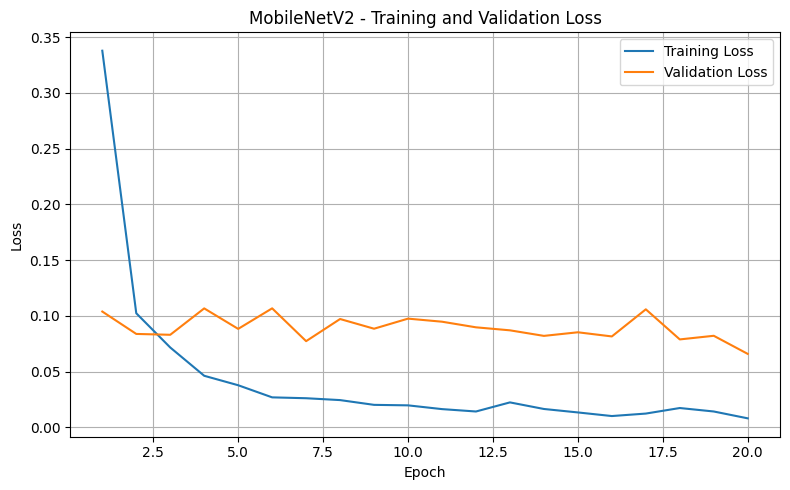

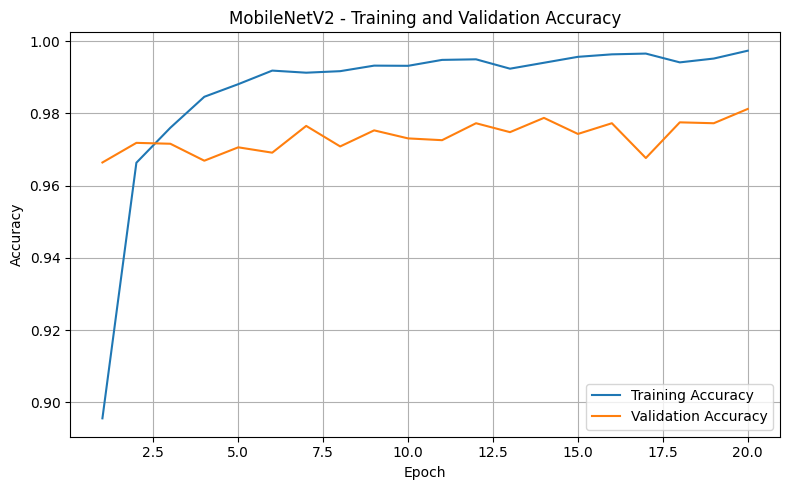

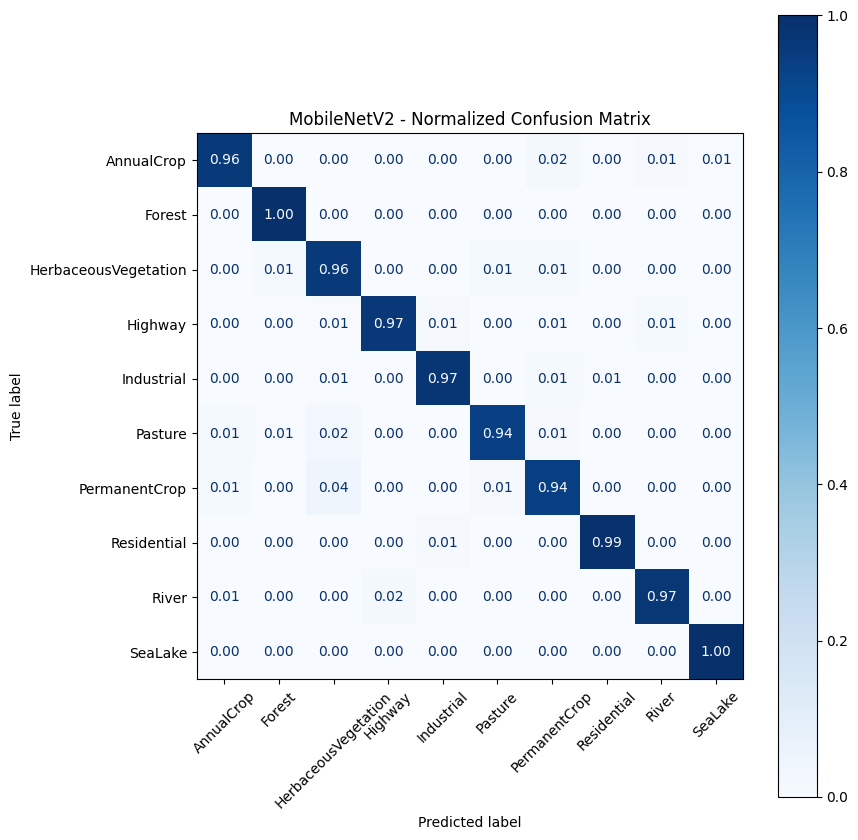

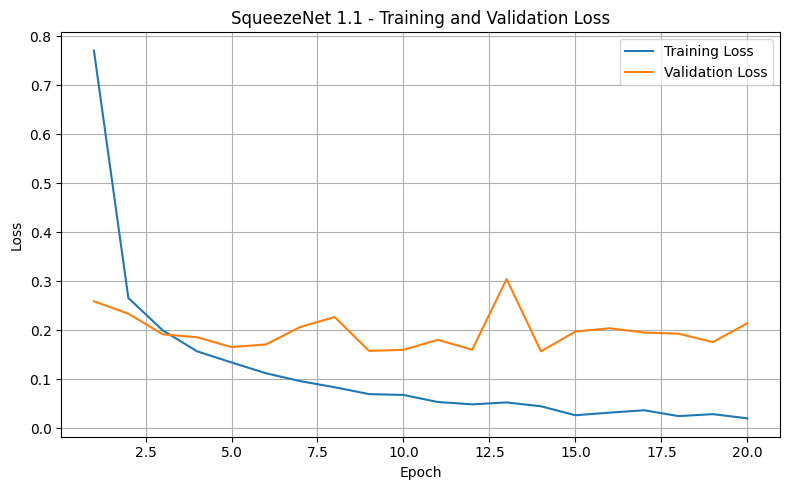

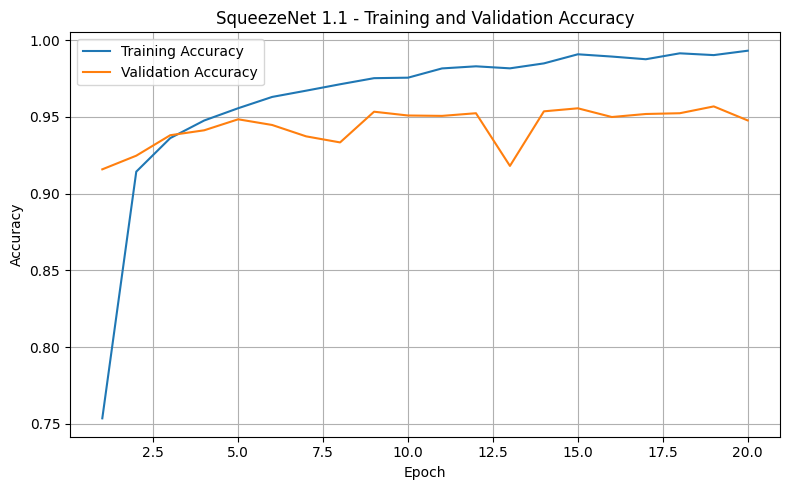

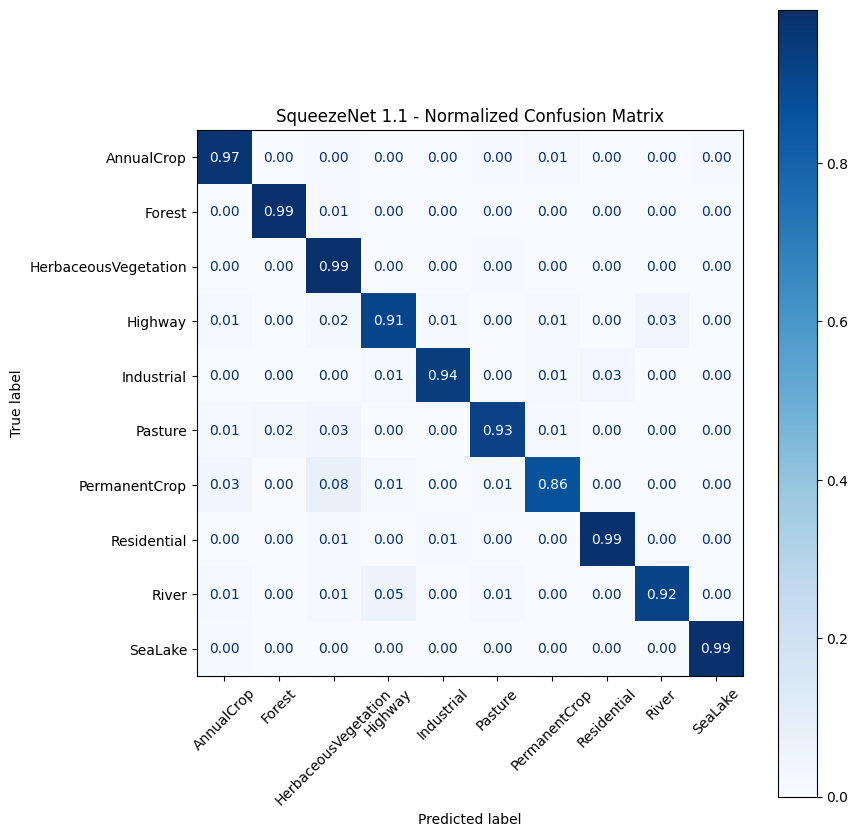

In [11]:
for name in networks:
    label = DISPLAY_NAMES[name]
    plot_training_history(histories[name], model_name=label)
    plot_confusion_matrix(results[name]['confusion_matrix'], class_names, model_name=label)

## 2.5 Comparison with custom Model B

In [12]:
section1_reference = [
    {'Model': 'Model B', 'Total parameters': 59_301, 'FP32 weights (MiB)': 59_301*4/2**20,
     'MACs/image (M)': 2.06, 'Test accuracy (%)': 84.86},
    {'Model': 'Model A', 'Total parameters': 914_122, 'FP32 weights (MiB)': 914_122*4/2**20,
     'MACs/image (M)': 60.70, 'Test accuracy (%)': 92.30},
]
comparison_columns = ['Model', 'Total parameters', 'FP32 weights (MiB)',
                      'MACs/image (M)', 'Test accuracy (%)']
comparison = pd.concat([pd.DataFrame(section1_reference), sota_table], ignore_index=True)
display(comparison[comparison_columns].round(3))

# Files used for the report. No test numbers are hard-coded for the SOTA models.
sota_table.to_csv(RESULTS_DIR / 'sota_metrics.csv', index=False)
comparison[comparison_columns].to_csv(RESULTS_DIR / 'model_comparison.csv', index=False)
for name, history in histories.items():
    pd.DataFrame(history).to_csv(RESULTS_DIR / f'{name}_history.csv', index=False)

metadata = {
    'seed': SEED, 'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
    'epochs': EPOCHS, 'optimizer': 'Adam', 'learning_rate': LR,
    'pretraining': 'TorchVision ImageNet-1K V1', 'fine_tuning': 'all layers',
    'checkpoint_selection': 'best validation accuracy',
    'split_sizes': split_sizes, 'classes': class_names,
    'normalization_mean': mean.tolist(), 'normalization_std': std.tolist(),
    'torch_version': torch.__version__, 'device': str(DEVICE),
    'best_epochs': {name: int(s['best_epoch']) for name, s in selections.items()},
    'test_confusion_matrices': {name: results[name]['confusion_matrix'].tolist()
                                for name in networks},
}
(RESULTS_DIR / 'experiment_metadata.json').write_text(json.dumps(metadata, indent=2))
print(f'Saved results tables, histories, and experiment metadata to: {RESULTS_DIR}')

,Model,Total parameters,FP32 weights (MiB),MACs/image (M),Test accuracy (%)
0,Model B,59301,0.226,2.060,84.860
1,Model A,914122,3.487,60.700,92.300
2,MobileNetV2,2236682,8.532,24.461,97.111
3,SqueezeNet 1.1,727626,2.776,17.023,95.358


Saved results tables, histories, and experiment metadata to: /content/EN3150_Assignment_03/results/section02
